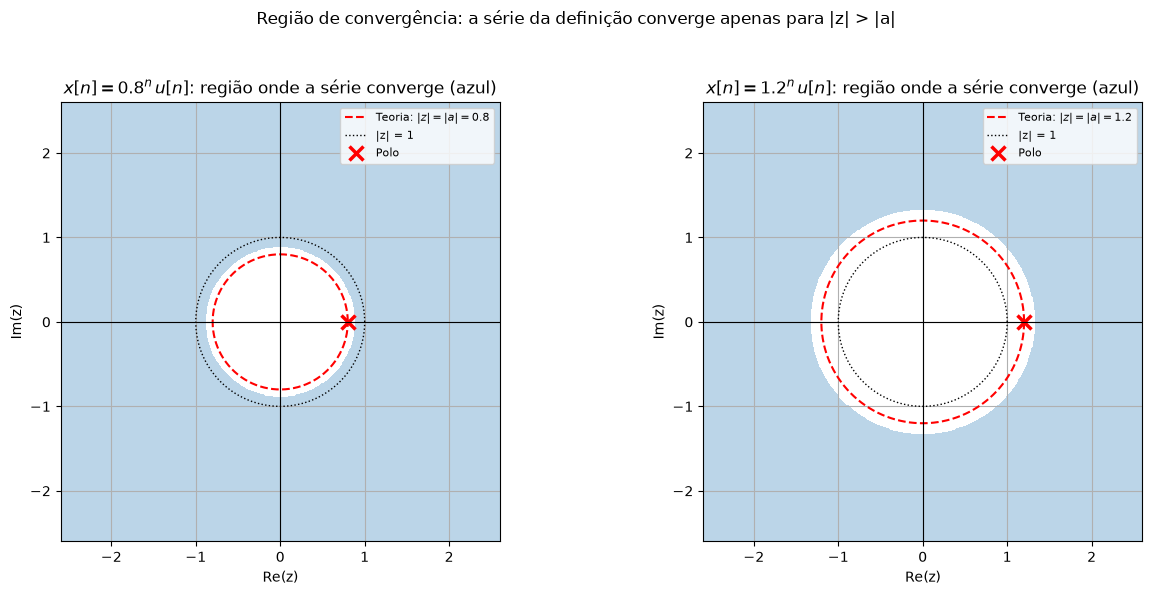

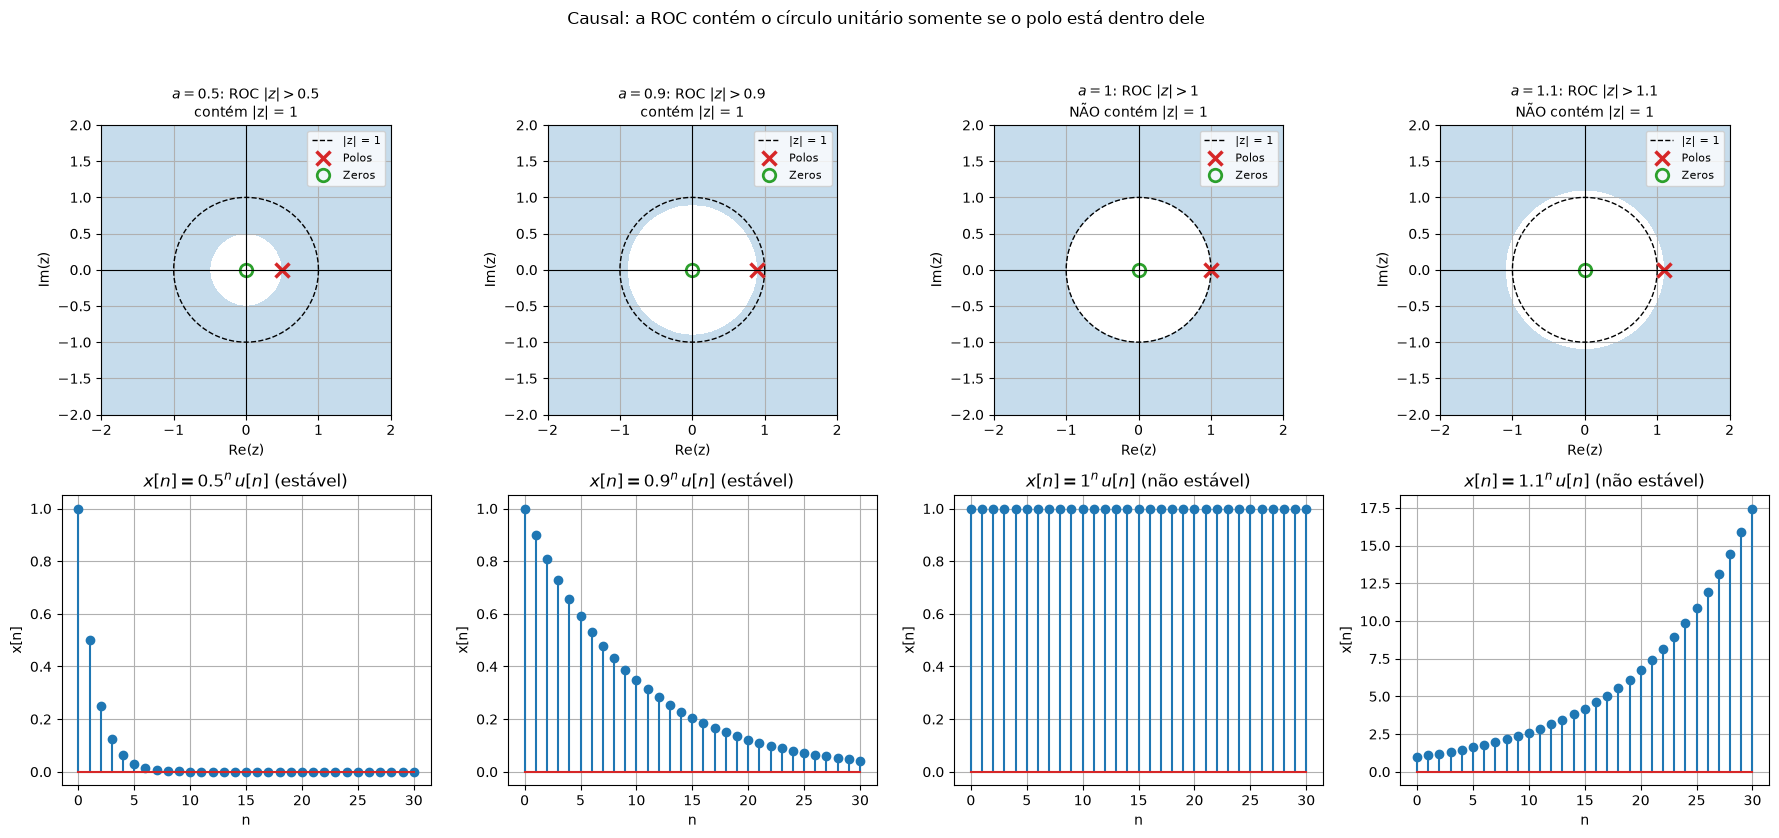

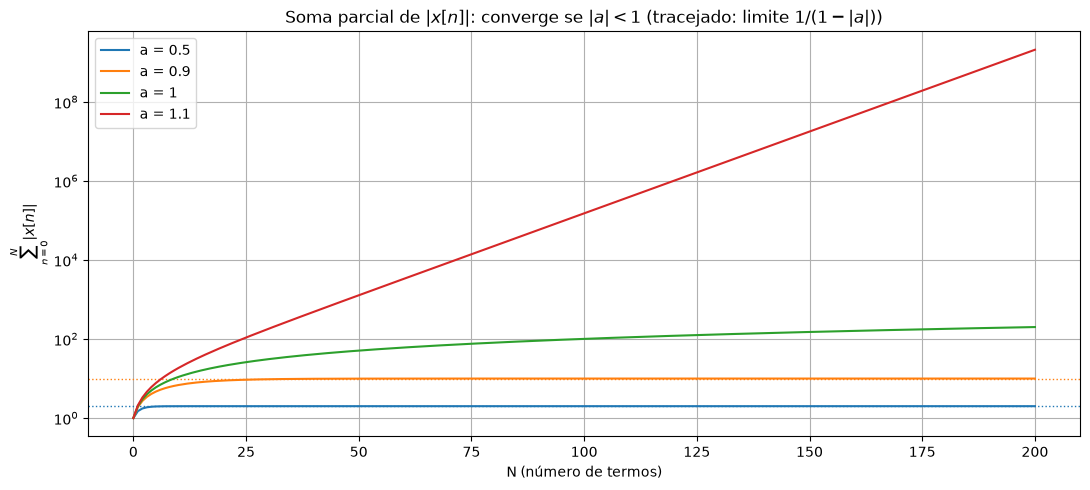

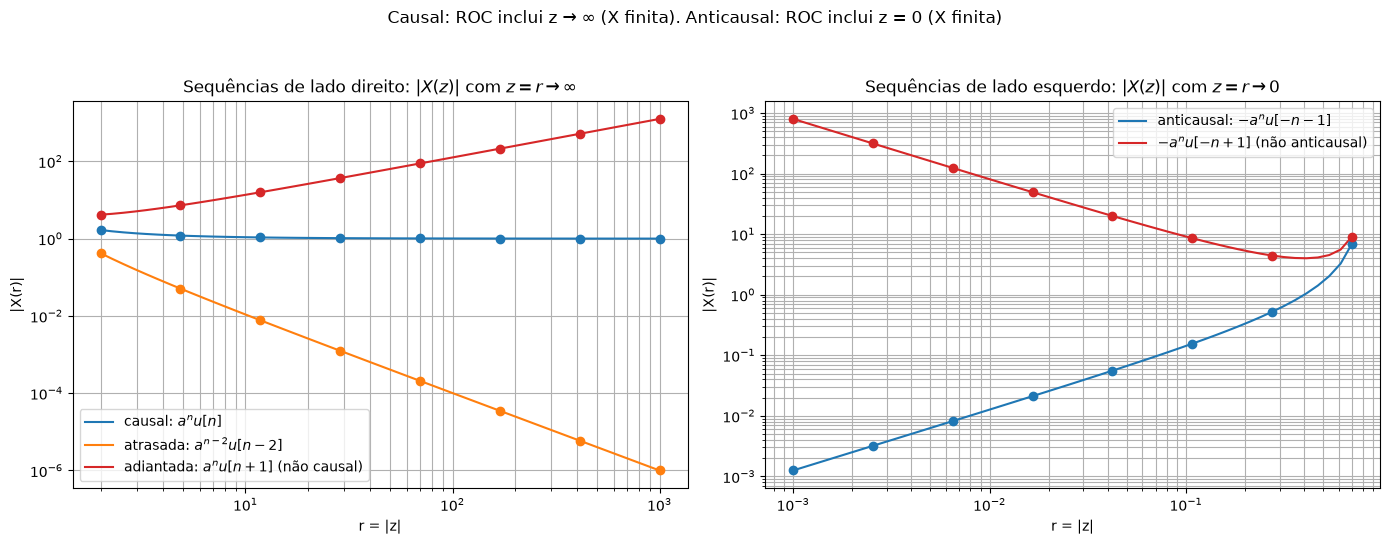

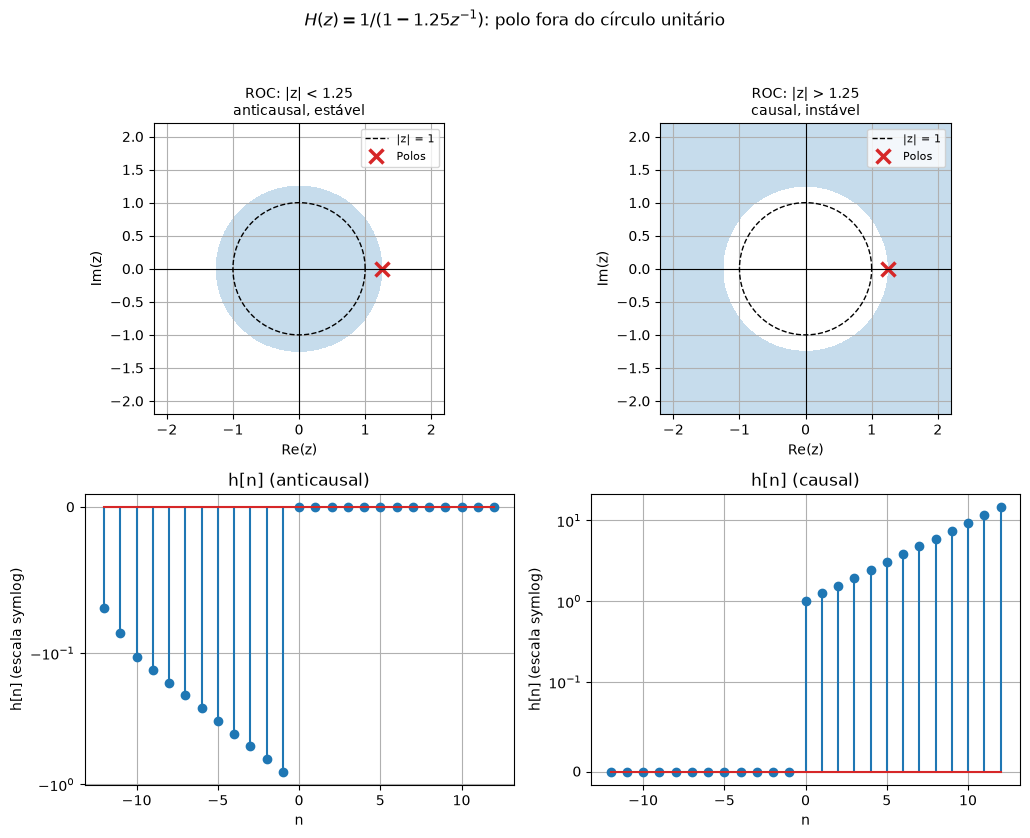

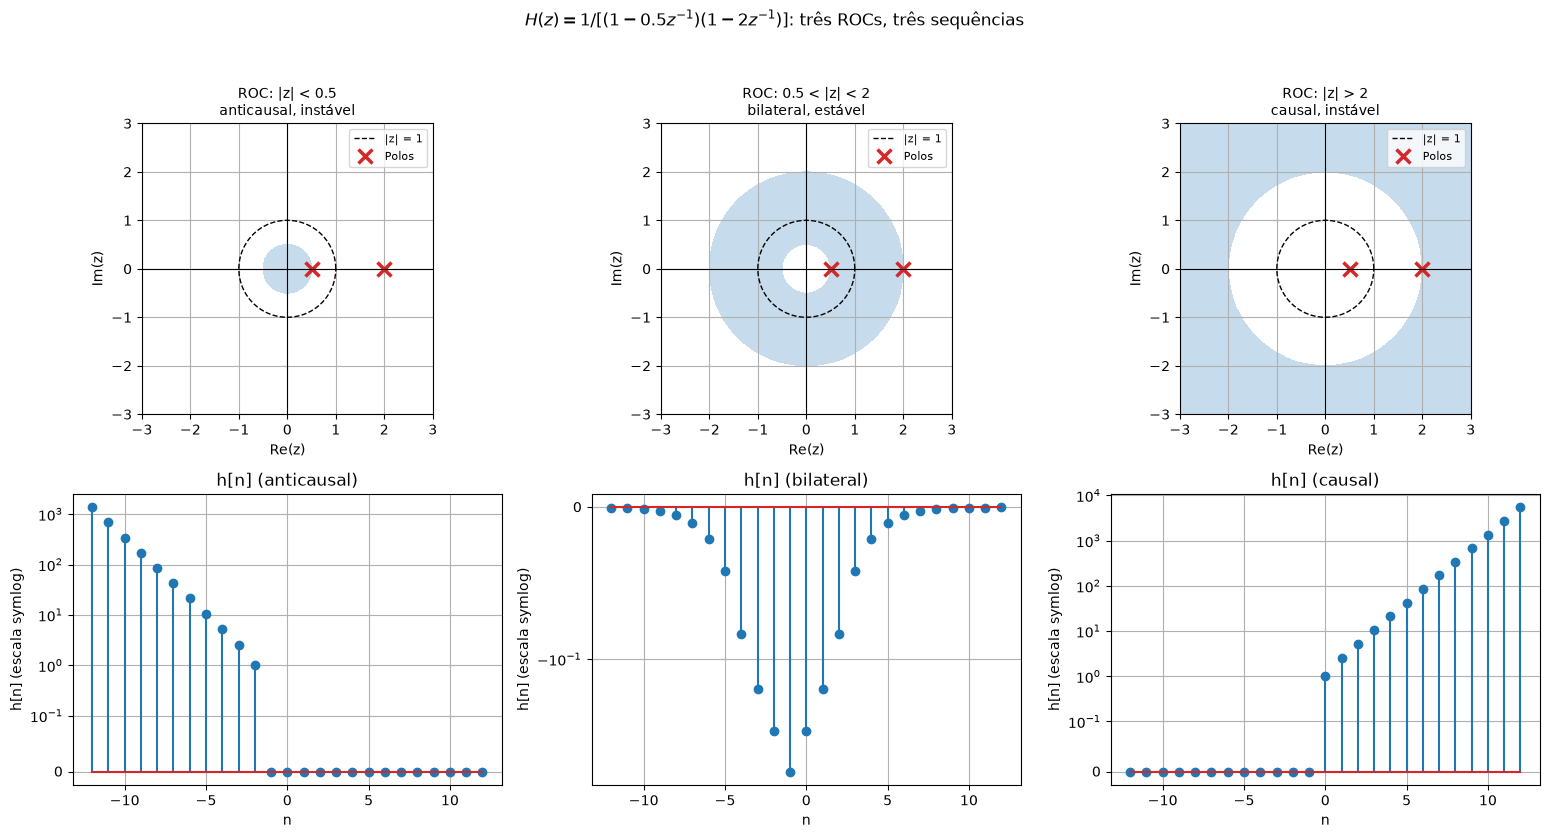

REGIÃO DE CONVERGÊNCIA E x[n] = a^n u[n]
X(z) = 1 / (1 - a z^-1),  ROC: |z| > |a|  (sequência causal)

Teste numérico de convergência da série (grade 401 x 401, M = 300 termos)
     a      Concordância com |z| > |a|
  0.80                        100.00 %
  1.20                        100.00 %
(Pontos a menos de 20% da fronteira |z| = |a| foram excluídos da contagem:
 com número finito de termos, a transição é gradual.)


ESTABILIDADE: ROC CONTÉM O CÍRCULO UNITÁRIO?
     a           ROC    Contém |z|=1     sum|x[n]| (200)     1/(1-|a|)    Estabilidade
  0.50     |z| > 0.5             sim                   2        2.0000         ESTÁVEL
  0.90     |z| > 0.9             sim                  10       10.0000         ESTÁVEL
 -0.90     |z| > 0.9             sim                  10       10.0000         ESTÁVEL
  1.00       |z| > 1             não                 201             -        MARGINAL
  1.10     |z| > 1.1             não         2.08896e+09             -        INSTÁVEL


CAUSAL

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURAÇÕES DA SIMULAÇÃO
# ============================================================

A_REF = 0.8                            # Valor de a da sequência de referência x[n] = a^n u[n]
lista_a = [0.5, 0.9, 1.0, 1.1]         # Valores de a para o estudo de estabilidade

NM = 400                               # Termos usados nas somas diretas da definição
M_ROC = 300                            # Termos usados no teste numérico de convergência
N_ABS = 200                            # Termos usados em sum|x[n]|

n_plot = np.arange(0, 31)              # Índices para os gráficos das sequências
n_h = np.arange(-12, 13)               # Índices para os gráficos de h[n]


# ============================================================
# 2. TRANSFORMADA-Z PELA DEFINIÇÃO
# ============================================================

def transformada_z_direta(x, n, z):
    """
    Calcula a Transformada-Z diretamente pela definição:

    X(z) = sum( x[n] * z^(-n) )

    x : valores da sequência
    n : índices correspondentes
    z : ponto (ou vetor de pontos) do plano complexo
    """

    z = np.atleast_1d(np.asarray(z, dtype=complex))

    potencias = z[None, :] ** (-n[:, None].astype(float))

    return np.sum(x[:, None] * potencias, axis=0)


def X_fechada(z, a):
    """
    X(z) = 1 / (1 - a z^-1), para x[n] = a^n u[n].
    """

    return 1 / (1 - a / z)


# ============================================================
# 3. TESTE NUMÉRICO DE CONVERGÊNCIA (ROC)
# ============================================================

def mapa_convergencia(a, grade, M=M_ROC, tol=1e-6):
    """
    Testa, em cada ponto z da grade, se a série de x[n] = a^n u[n]
    converge absolutamente:

    sum |a|^n |z|^-n

    O ponto é considerado convergente se a soma de n = M/2 até M
    é desprezível (série geométrica de razão |a|/|z|).
    """

    modulo = np.maximum(np.abs(grade), 1e-12)
    razao = abs(a) / modulo

    soma = np.zeros_like(modulo)
    soma_meio = np.zeros_like(modulo)
    termo = np.ones_like(modulo)

    with np.errstate(over="ignore", invalid="ignore"):
        for n in range(M + 1):
            soma = soma + termo

            if n == M // 2:
                soma_meio = soma.copy()

            termo = termo * razao

        diferenca = soma - soma_meio

    return np.isfinite(diferenca) & (diferenca < tol)


# ============================================================
# 4. ROC, CAUSALIDADE E ESTABILIDADE DE SISTEMAS RACIONAIS
# ============================================================

def rocs_possiveis(polos, tol=1e-9):
    """
    Regiões de convergência possíveis de uma X(z) racional:
    anéis delimitados pelos módulos distintos dos polos.

    Retorna uma lista de pares (r_interno, r_externo).
    """

    modulos = sorted(set(np.round(np.abs(np.array(polos, dtype=complex)), 9)))

    fronteiras = [0.0] + modulos + [np.inf]

    return [(fronteiras[i], fronteiras[i + 1]) for i in range(len(fronteiras) - 1)]


def descrever_roc(r_in, r_out):
    """
    Texto da ROC.
    """

    if r_in == 0 and np.isinf(r_out):
        return "todo z"

    if r_in == 0:
        return f"|z| < {r_out:g}"

    if np.isinf(r_out):
        return f"|z| > {r_in:g}"

    return f"{r_in:g} < |z| < {r_out:g}"


def tipo_da_roc(r_in, r_out):
    """
    Relação entre a ROC e o tipo de sequência:

    exterior de um círculo -> lado direito (causal se incluir o infinito)
    interior de um círculo -> lado esquerdo (anticausal)
    anel                   -> bilateral
    """

    if np.isinf(r_out) and r_in > 0:
        return "causal"

    if r_in == 0 and not np.isinf(r_out):
        return "anticausal"

    return "bilateral"


def contem_circulo_unitario(r_in, r_out):
    """
    O sistema é estável (h[n] absolutamente somável) se, e somente se,
    a ROC contém o círculo unitário.
    """

    return r_in < 1.0 < r_out


def h_por_roc(n, num, den, r_in, r_out):
    """
    Resposta ao impulso associada a uma ROC (polos simples), por
    frações parciais:

    H(z) = d + sum( c_k / (1 - p_k z^-1) )

    polo com |p| <= r_in   -> c_k p_k^n u[n]          (lado direito)
    polo com |p| >= r_out  -> -c_k p_k^n u[-n-1]      (lado esquerdo)
    """

    N = max(len(num), len(den)) - 1

    Bz = np.pad(num, (0, N + 1 - len(num)))
    Az = np.pad(den, (0, N + 1 - len(den)))

    polos = np.roots(Az)

    c = np.polyval(Bz, polos) / (polos * np.polyval(np.polyder(Az), polos))
    d = Bz[0] / Az[0] - np.sum(c)

    h = d * (n == 0).astype(complex)

    for pk, ck in zip(polos, c):
        if abs(pk) <= r_in + 1e-9:
            h += ck * (pk ** n.astype(float)) * (n >= 0)
        else:
            h -= ck * (pk ** n.astype(float)) * (n <= -1)

    return np.real(h)


def ponto_dentro_da_roc(r_in, r_out):
    """
    Ponto de teste z0 no interior da ROC.
    """

    if r_in == 0:
        raio = r_out / 2
    elif np.isinf(r_out):
        raio = 1.5 * r_in
    else:
        raio = np.sqrt(r_in * r_out)

    return raio * np.exp(0.7j)


# ============================================================
# 5. FUNÇÃO AUXILIAR: PLANO-z COM REGIÃO DE CONVERGÊNCIA
# ============================================================

def desenhar_plano_z(eixo, polos, zeros, regiao, titulo, limite=2.6):
    """
    Desenha o plano-z com círculo unitário, polos, zeros e a ROC
    (regiao é uma função do módulo |z| que devolve True dentro da ROC).
    """

    g = np.linspace(-limite, limite, 600)
    Xg, Yg = np.meshgrid(g, g)
    modulo = np.hypot(Xg, Yg)

    eixo.contourf(Xg, Yg, regiao(modulo).astype(float),
                  levels=[0.5, 1.5], colors=["tab:blue"], alpha=0.25)

    theta = np.linspace(0, 2 * np.pi, 400)
    eixo.plot(np.cos(theta), np.sin(theta), "k--", linewidth=1, label="|z| = 1")

    eixo.plot(np.real(polos), np.imag(polos), "x", color="tab:red",
              markersize=10, markeredgewidth=2.5, label="Polos")

    if len(zeros) > 0:
        eixo.plot(np.real(zeros), np.imag(zeros), "o", color="tab:green",
                  markersize=9, markerfacecolor="none", markeredgewidth=2, label="Zeros")

    eixo.axhline(0, color="k", linewidth=0.8)
    eixo.axvline(0, color="k", linewidth=0.8)

    eixo.set_aspect("equal")
    eixo.set_xlim(-limite, limite)
    eixo.set_ylim(-limite, limite)

    eixo.set_title(titulo, fontsize=10)
    eixo.set_xlabel("Re(z)")
    eixo.set_ylabel("Im(z)")

    eixo.legend(loc="upper right", fontsize=8)
    eixo.grid(True)


# ============================================================
# 6. ROC DE x[n] = a^n u[n]: TEORIA x TESTE NUMÉRICO
# ============================================================

g = np.linspace(-2.6, 2.6, 401)
Xg, Yg = np.meshgrid(g, g)
Zg = Xg + 1j * Yg

theta = np.linspace(0, 2 * np.pi, 400)

fig, eixos = plt.subplots(1, 2, figsize=(13, 6))

concordancia = {}

for eixo, a in zip(eixos, [A_REF, 1.2]):
    numerico = mapa_convergencia(a, Zg)

    eixo.contourf(Xg, Yg, numerico.astype(float), levels=[0.5, 1.5],
                  colors=["tab:blue"], alpha=0.3)

    eixo.plot(abs(a) * np.cos(theta), abs(a) * np.sin(theta), "r--", linewidth=1.5,
              label=rf"Teoria: $|z|=|a|={abs(a):g}$")
    eixo.plot(np.cos(theta), np.sin(theta), "k:", linewidth=1, label="|z| = 1")
    eixo.plot([a], [0], "rx", markersize=10, markeredgewidth=2.5, label="Polo")

    eixo.axhline(0, color="k", linewidth=0.8)
    eixo.axvline(0, color="k", linewidth=0.8)

    eixo.set_aspect("equal")
    eixo.set_title(rf"$x[n]={a:g}^n\,u[n]$: região onde a série converge (azul)")
    eixo.set_xlabel("Re(z)")
    eixo.set_ylabel("Im(z)")
    eixo.legend(loc="upper right", fontsize=8)
    eixo.grid(True)

    # Concordância com a teoria, fora de uma faixa de transição (±20%)
    teoria = np.abs(Zg) > abs(a)
    fora_da_faixa = np.abs(np.abs(Zg) / abs(a) - 1) > 0.2

    concordancia[a] = np.mean((numerico == teoria)[fora_da_faixa]) * 100

plt.suptitle("Região de convergência: a série da definição converge apenas para |z| > |a|")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


# ============================================================
# 7. ESTABILIDADE: ROC x CÍRCULO UNITÁRIO
# ============================================================

fig, eixos = plt.subplots(2, 4, figsize=(18, 8.5))

for j, a in enumerate(lista_a):
    estavel = abs(a) < 1

    desenhar_plano_z(eixos[0, j], np.array([a]), np.array([0.0]),
                     lambda m, a=a: m > abs(a),
                     rf"$a={a:g}$: ROC $|z|>{abs(a):g}$" + "\n"
                     + ("contém |z| = 1" if estavel else "NÃO contém |z| = 1"),
                     limite=2.0)

    x = a ** n_plot.astype(float)
    eixos[1, j].stem(n_plot, x)
    eixos[1, j].set_title(rf"$x[n]={a:g}^n\,u[n]$ ({'estável' if estavel else 'não estável'})")
    eixos[1, j].set_xlabel("n")
    eixos[1, j].set_ylabel("x[n]")
    eixos[1, j].grid(True)

plt.suptitle("Causal: a ROC contém o círculo unitário somente se o polo está dentro dele")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# ============================================================
# 8. ESTABILIDADE: SOMABILIDADE ABSOLUTA DE x[n]
# ============================================================

n_soma = np.arange(0, N_ABS + 1)

plt.figure(figsize=(11, 5))

for a, cor in zip(lista_a, ["C0", "C1", "C2", "C3"]):
    soma_parcial = np.cumsum(np.abs(a) ** n_soma.astype(float))

    plt.semilogy(n_soma, soma_parcial, color=cor, label=f"a = {a:g}")

    if abs(a) < 1:
        plt.axhline(1 / (1 - abs(a)), color=cor, linestyle=":", linewidth=1)

plt.title(r"Soma parcial de $|x[n]|$: converge se $|a|<1$ (tracejado: limite $1/(1-|a|)$)")
plt.xlabel("N (número de termos)")
plt.ylabel(r"$\sum_{n=0}^{N}|x[n]|$")

plt.legend()
plt.grid(True, which="both")
plt.tight_layout()
plt.show()


# ============================================================
# 9. CAUSALIDADE: A ROC INCLUI O INFINITO (OU O ZERO)
# ============================================================

a = A_REF

n_c = np.arange(0, NM + 1)

# Causal: x[n] = a^n u[n]               -> X(z) = 1 / (1 - a z^-1)
x_causal = a ** n_c.astype(float)

# Atrasada: x[n] = a^(n-2) u[n-2]       -> X(z) = z^-2 / (1 - a z^-1)
n_atr = np.arange(2, NM + 1)
x_atrasada = a ** (n_atr - 2).astype(float)

# Adiantada (não causal): x[n] = a^n u[n+1]  -> X(z) = z/a + 1/(1 - a z^-1)
n_adi = np.arange(-1, NM + 1)
x_adiantada = a ** n_adi.astype(float)

r_grande = np.logspace(0.3, 3, 50)

X_causal = np.abs(1 / (1 - a / r_grande))
X_atrasada = np.abs(r_grande ** (-2.0) / (1 - a / r_grande))
X_adiantada = np.abs(r_grande / a + 1 / (1 - a / r_grande))

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))

eixos[0].loglog(r_grande, X_causal, color="C0", label=r"causal: $a^n u[n]$")
eixos[0].loglog(r_grande, X_atrasada, color="C1", label=r"atrasada: $a^{n-2}u[n-2]$")
eixos[0].loglog(r_grande, X_adiantada, color="C3", label=r"adiantada: $a^n u[n+1]$ (não causal)")

# Conferência com a soma da definição (marcadores)
r_amostra = r_grande[::7]

eixos[0].loglog(r_amostra, np.abs(transformada_z_direta(x_causal, n_c, r_amostra)), "o", color="C0")
eixos[0].loglog(r_amostra, np.abs(transformada_z_direta(x_atrasada, n_atr, r_amostra)), "o", color="C1")
eixos[0].loglog(r_amostra, np.abs(transformada_z_direta(x_adiantada, n_adi, r_amostra)), "o", color="C3")

eixos[0].set_title(r"Sequências de lado direito: $|X(z)|$ com $z=r\to\infty$")
eixos[0].set_xlabel("r = |z|")
eixos[0].set_ylabel("|X(r)|")

# Anticausal: x[n] = -a^n u[-n-1]   -> X(z) = 1 / (1 - a z^-1)
n_ac = np.arange(-NM, 0)
x_anticausal = -(a ** n_ac.astype(float))

# Não anticausal: x[n] = -a^n u[-n+1] -> X(z) = -a/z - 1/(1 - z/a)
n_nac = np.arange(-NM, 2)
x_nao_anticausal = -(a ** n_nac.astype(float))

r_pequeno = np.logspace(-3, np.log10(0.7), 50)

Y_ac = np.abs(1 / (1 - a / r_pequeno))
Y_nac = np.abs(-a / r_pequeno - 1 / (1 - r_pequeno / a))

eixos[1].loglog(r_pequeno, Y_ac, color="C0", label=r"anticausal: $-a^n u[-n-1]$")
eixos[1].loglog(r_pequeno, Y_nac, color="C3", label=r"$-a^n u[-n+1]$ (não anticausal)")

r_amostra = r_pequeno[::7]

eixos[1].loglog(r_amostra, np.abs(transformada_z_direta(x_anticausal, n_ac, r_amostra)), "o", color="C0")
eixos[1].loglog(r_amostra, np.abs(transformada_z_direta(x_nao_anticausal, n_nac, r_amostra)), "o", color="C3")

eixos[1].set_title(r"Sequências de lado esquerdo: $|X(z)|$ com $z=r\to 0$")
eixos[1].set_xlabel("r = |z|")
eixos[1].set_ylabel("|X(r)|")

for eixo in eixos:
    eixo.legend()
    eixo.grid(True, which="both")

plt.suptitle("Causal: ROC inclui z → ∞ (X finita). Anticausal: ROC inclui z = 0 (X finita)")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


# ============================================================
# 10. UMA MESMA H(z), VÁRIAS ROCs: CAUSALIDADE x ESTABILIDADE
# ============================================================

def figura_opcoes_roc(polos, titulo, limite=3.0):
    """
    Para H(z) = 1 / prod(1 - p_k z^-1), desenha cada ROC possível
    (plano-z) e a resposta ao impulso correspondente.
    """

    den = np.real(np.poly(polos))
    num = np.array([1.0])

    opcoes = rocs_possiveis(polos)

    fig, eixos = plt.subplots(2, len(opcoes), figsize=(5.2 * len(opcoes), 8.5))

    for j, (r_in, r_out) in enumerate(opcoes):
        tipo = tipo_da_roc(r_in, r_out)
        estavel = contem_circulo_unitario(r_in, r_out)

        desenhar_plano_z(eixos[0, j], polos, [],
                         lambda m, ri=r_in, ro=r_out: (m > ri) & (m < ro),
                         f"ROC: {descrever_roc(r_in, r_out)}\n{tipo}, "
                         + ("estável" if estavel else "instável"),
                         limite=limite)

        h = h_por_roc(n_h, num, den, r_in, r_out)

        eixos[1, j].stem(n_h, h)
        eixos[1, j].set_yscale("symlog", linthresh=0.1)
        eixos[1, j].set_title(f"h[n] ({tipo})")
        eixos[1, j].set_xlabel("n")
        eixos[1, j].set_ylabel("h[n] (escala symlog)")
        eixos[1, j].grid(True)

    plt.suptitle(titulo)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


figura_opcoes_roc(np.array([1.25]),
                  r"$H(z)=1/(1-1.25z^{-1})$: polo fora do círculo unitário", limite=2.2)

figura_opcoes_roc(np.array([0.5, 2.0]),
                  r"$H(z)=1/[(1-0.5z^{-1})(1-2z^{-1})]$: três ROCs, três sequências")


# ============================================================
# 11. RESULTADOS: ROC DE a^n u[n]
# ============================================================

print("REGIÃO DE CONVERGÊNCIA E x[n] = a^n u[n]")
print("=" * 90)
print("X(z) = 1 / (1 - a z^-1),  ROC: |z| > |a|  (sequência causal)")

print("\nTeste numérico de convergência da série (grade 401 x 401, M = 300 termos)")
print(f"{'a':>6}{'Concordância com |z| > |a|':>32}")

for a_teste, pct in concordancia.items():
    print(f"{a_teste:6.2f}{pct:30.2f} %")

print("(Pontos a menos de 20% da fronteira |z| = |a| foram excluídos da contagem:")
print(" com número finito de termos, a transição é gradual.)")


# ============================================================
# 12. RESULTADOS: ESTABILIDADE DE a^n u[n]
# ============================================================

print("\n\nESTABILIDADE: ROC CONTÉM O CÍRCULO UNITÁRIO?")
print("=" * 90)
print(f"{'a':>6}{'ROC':>14}{'Contém |z|=1':>16}{'sum|x[n]| (200)':>20}{'1/(1-|a|)':>14}{'Estabilidade':>16}")

for a_teste in [0.5, 0.9, -0.9, 1.0, 1.1]:
    soma = np.sum(np.abs(a_teste) ** n_soma.astype(float))
    contem = contem_circulo_unitario(abs(a_teste), np.inf)

    if abs(a_teste) < 1:
        txt_teor = f"{1 / (1 - abs(a_teste)):14.4f}"
        classe = "ESTÁVEL"
    else:
        txt_teor = f"{'-':>14}"
        classe = "MARGINAL" if abs(a_teste) == 1 else "INSTÁVEL"

    print(f"{a_teste:6.2f}{'|z| > ' + format(abs(a_teste), 'g'):>14}{('sim' if contem else 'não'):>16}"
          f"{soma:20.6g}{txt_teor}{classe:>16}")


# ============================================================
# 13. RESULTADOS: CAUSALIDADE E COMPORTAMENTO EM z -> INFINITO
# ============================================================

print("\n\nCAUSALIDADE: VALOR DE X(z) QUANDO |z| -> INFINITO (z = 1e6)")
print("=" * 90)
print(f"{'Sequência':<30}{'x[0]':>6}{'|X(z=1e6)|':>14}   Interpretação")

z_grande = 1e6

casos_inf = [
    ("a^n u[n] (causal)", 1.0, abs(X_fechada(z_grande, a)), "finita = x[0]: ROC inclui infinito"),
    ("a^(n-2) u[n-2] (atrasada)", 0.0, abs(z_grande ** (-2.0) / (1 - a / z_grande)), "finita = x[0] = 0"),
    ("a^n u[n+1] (adiantada)", 1.0,
     abs(z_grande / a + X_fechada(z_grande, a)), "diverge: ROC exclui o infinito"),
]

for nome, x0, valor, texto in casos_inf:
    print(f"{nome:<30}{x0:6.1f}{valor:14.4g}   {texto}")


# ============================================================
# 14. RESULTADOS: ROCs POSSÍVEIS, CAUSALIDADE E ESTABILIDADE
# ============================================================

print("\n\nROCs POSSÍVEIS DE H(z) = 1 / prod(1 - p_k z^-1)")
print("=" * 118)
print(f"{'Polos':<22}{'ROC':<18}{'Tipo':<12}{'Contém |z|=1':>14}{'sum|h| (|n|<=60)':>20}{'Erro série x H(z0)':>22}")

n_dir = np.arange(-NM, NM + 1)
n_60 = np.arange(-60, 61)

conjuntos = [
    ("0.8", [0.8]),
    ("1.25", [1.25]),
    ("1.0", [1.0]),
    ("0.5, 2", [0.5, 2.0]),
    ("0.5, 0.9", [0.5, 0.9]),
    ("0.9 e^(±j pi/3)", [0.9 * np.exp(1j * np.pi / 3), 0.9 * np.exp(-1j * np.pi / 3)]),
    ("0.5, 1.5, 2.5", [0.5, 1.5, 2.5]),
]

for nome, polos in conjuntos:
    den = np.real(np.poly(polos))
    num = np.array([1.0])

    for r_in, r_out in rocs_possiveis(polos):
        h_400 = h_por_roc(n_dir, num, den, r_in, r_out)
        h_60 = h_por_roc(n_60, num, den, r_in, r_out)

        # Série da definição em um ponto z0 dentro da ROC x H(z0) em forma fechada
        z0 = ponto_dentro_da_roc(r_in, r_out)

        serie = transformada_z_direta(h_400, n_dir, z0)[0]
        fechada = 1 / np.polyval(den[::-1], 1 / z0)

        erro = np.abs(serie - fechada)
        contem = contem_circulo_unitario(r_in, r_out)

        print(f"{nome:<22}{descrever_roc(r_in, r_out):<18}{tipo_da_roc(r_in, r_out):<12}"
              f"{('sim' if contem else 'não'):>14}{np.sum(np.abs(h_60)):20.4g}{erro:22.3e}")


# ============================================================
# 15. CONCLUSÕES
# ============================================================

print("\n\nCONCLUSÕES")
print("=" * 70)
print("A expressão de X(z) não basta: a ROC faz parte da transformada.")
print("X(z) = 1/(1 - a z^-1) tem duas sequências possíveis:")
print("      a^n u[n]        com ROC |z| > |a|  (causal)")
print("      -a^n u[-n-1]    com ROC |z| < |a|  (anticausal)")
print("Causalidade:")
print("Causal (lado direito): ROC é o exterior de um círculo e inclui z -> infinito.")
print("Para X(z) racional, causal exige grau do numerador <= grau do denominador.")
print("Anticausal (lado esquerdo): ROC é o interior de um círculo e inclui z = 0.")
print("Bilateral: ROC é um anel entre dois polos")
print("Estabilidade:")
print("h[n] é absolutamente somável se, e somente se, a ROC contém |z| = 1")
print("    (a DTFT existe exatamente nesse caso).")
print("Causal e estável: todos os polos dentro do círculo unitário.")
print("Um polo fora do círculo unitário pode ser estável se o sistema for")
print("    anticausal (ou bilateral): a ROC escolhida decide.")
print("Causal e estável simultaneamente: ROC |z| > max|p_k| com max|p_k| < 1.")

print("\nSimulação concluída!")